# Crop Recommendation Dataset Analysis

## Import Libraries

In [1]:
import sys
print(sys.executable)
print(sys.version)

c:\Users\aadit\AppData\Local\Programs\Python\Python313\python.exe
3.13.1 (tags/v3.13.1:0671451, Dec  3 2024, 19:06:28) [MSC v.1942 64 bit (AMD64)]


In [2]:
import pandas as pd
import numpy as np

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 50)

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

plt.rcParams['figure.figsize'] = (12,8)

# Machine Learning (used in later epics)
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# Model Evaluation
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score

## Read the Dataset

In [3]:
df = pd.read_csv("../dataset/Crop_recommendation.csv")


In [4]:
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [5]:
df.shape

(2200, 8)

In [6]:
df.columns


Index(['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label'], dtype='str')

In [7]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 137.6 KB


In [8]:
df.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


## Univariate Analysis


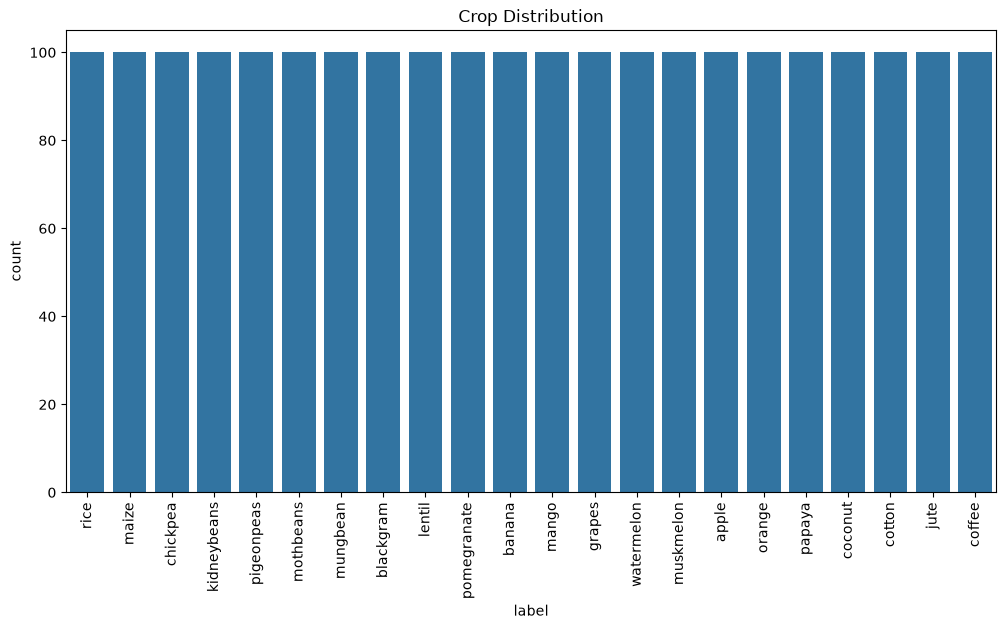

In [9]:
plt.figure(figsize=(12,6))
sns.countplot(x='label', data=df)
plt.xticks(rotation=90)
plt.title("Crop Distribution")
plt.show()

### Observation

The crop distribution is balanced, with each crop having approximately the same number of samples. This balanced distribution is beneficial for training machine learning models, as it reduces the risk of bias toward any particular crop.

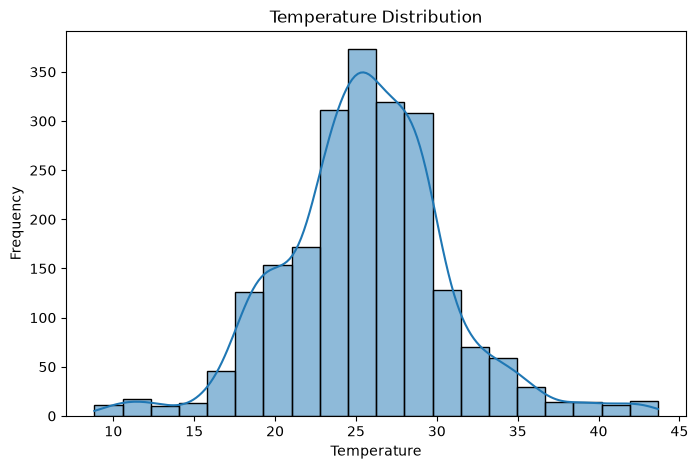

In [10]:
plt.figure(figsize=(8,5))
sns.histplot(df['temperature'], bins=20, kde=True)
plt.title("Temperature Distribution")
plt.xlabel("Temperature")
plt.ylabel("Frequency")
plt.show()

### Observation

The temperature values range from approximately 8°C to 43°C, with most samples concentrated between 20°C and 30°C. The highest frequency is around 25°C–28°C, indicating that most crops in the dataset grow under moderate temperature conditions.

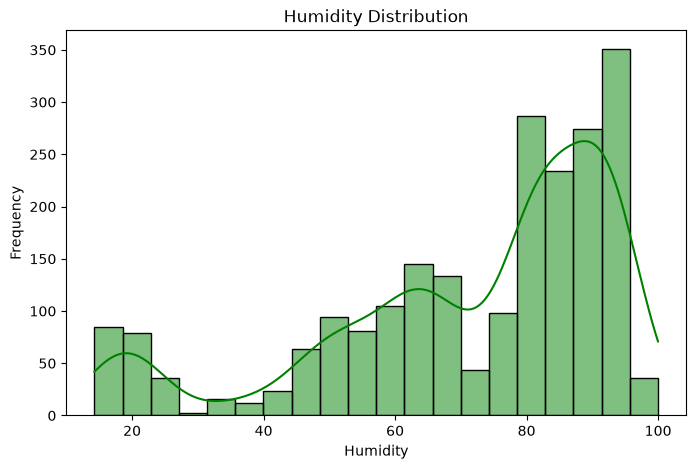

In [11]:
plt.figure(figsize=(8,5))
sns.histplot(df['humidity'], bins=20, kde=True, color='green')
plt.title("Humidity Distribution")
plt.xlabel("Humidity")
plt.ylabel("Frequency")
plt.show()

### Observation

The humidity values range from low to high levels, with most observations concentrated in the middle to higher humidity range. This indicates that the dataset contains crops suitable for different humidity conditions.

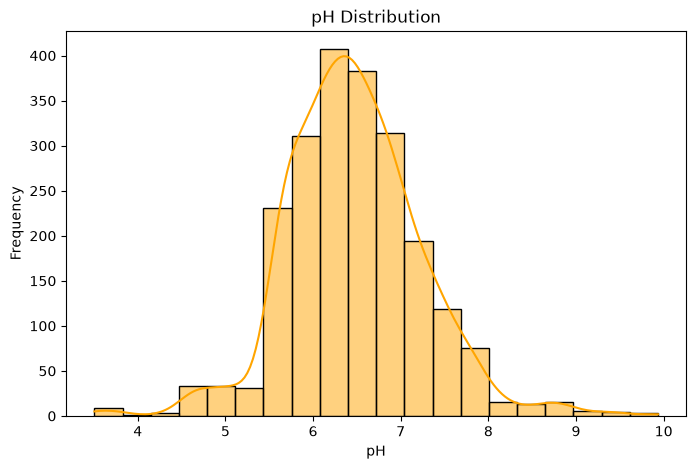

In [12]:
plt.figure(figsize=(8,5))
sns.histplot(df['ph'], bins=20, kde=True, color='orange')
plt.title("pH Distribution")
plt.xlabel("pH")
plt.ylabel("Frequency")
plt.show()

### Observation

Most soil pH values are between 5.5 and 7.5, indicating that the majority of crops prefer slightly acidic to neutral soil conditions.

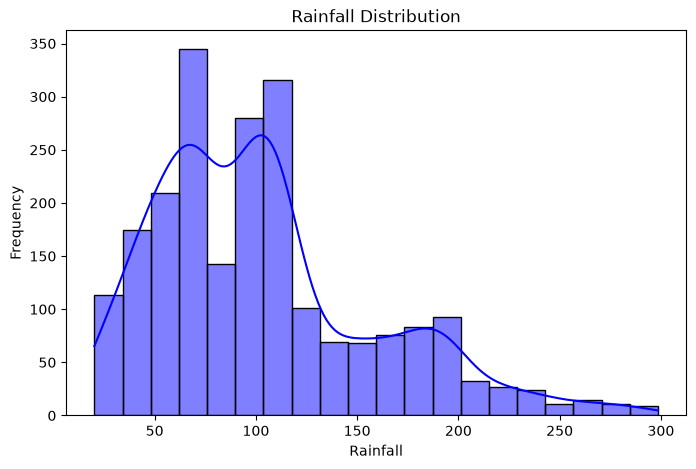

In [13]:
plt.figure(figsize=(8,5))
sns.histplot(df['rainfall'], bins=20, kde=True, color='blue')
plt.title("Rainfall Distribution")
plt.xlabel("Rainfall")
plt.ylabel("Frequency")
plt.show()

### Observation

Rainfall values vary over a wide range, showing that the dataset includes crops suitable for different rainfall conditions.

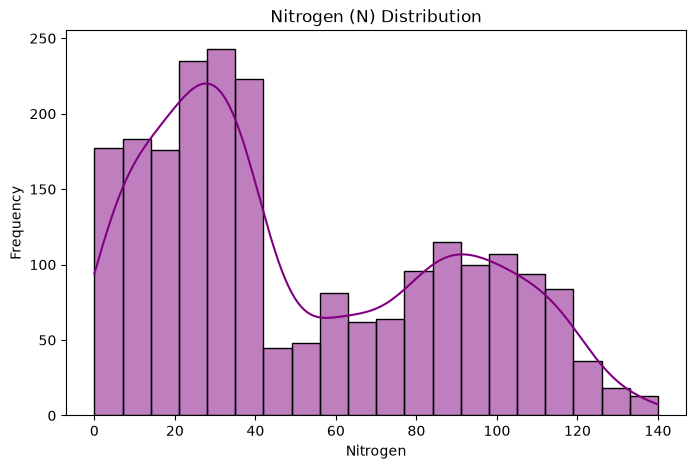

In [14]:
plt.figure(figsize=(8,5))
sns.histplot(df['N'], bins=20, kde=True, color='purple')
plt.title("Nitrogen (N) Distribution")
plt.xlabel("Nitrogen")
plt.ylabel("Frequency")
plt.show()

### Observation

Nitrogen values are spread across different levels, indicating variation in soil nutrient content among the crop samples.

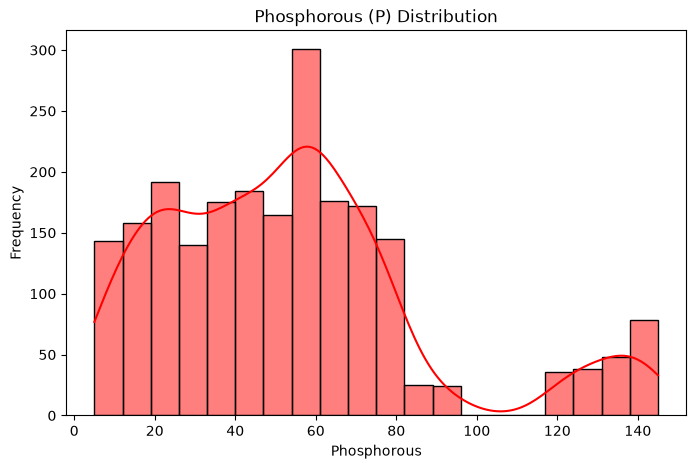

In [15]:
plt.figure(figsize=(8,5))
sns.histplot(df['P'], bins=20, kde=True, color='red')
plt.title("Phosphorous (P) Distribution")
plt.xlabel("Phosphorous")
plt.ylabel("Frequency")
plt.show()

### Observation

The phosphorous values show a broad distribution, suggesting that different crops require different phosphorous levels.

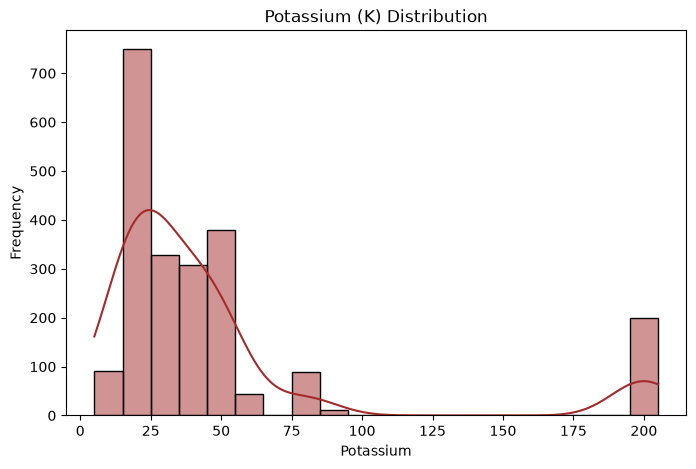

In [16]:
plt.figure(figsize=(8,5))
sns.histplot(df['K'], bins=20, kde=True, color='brown')
plt.title("Potassium (K) Distribution")
plt.xlabel("Potassium")
plt.ylabel("Frequency")
plt.show()

### Observation

Potassium values vary across the dataset, reflecting different potassium requirements for various crop types.

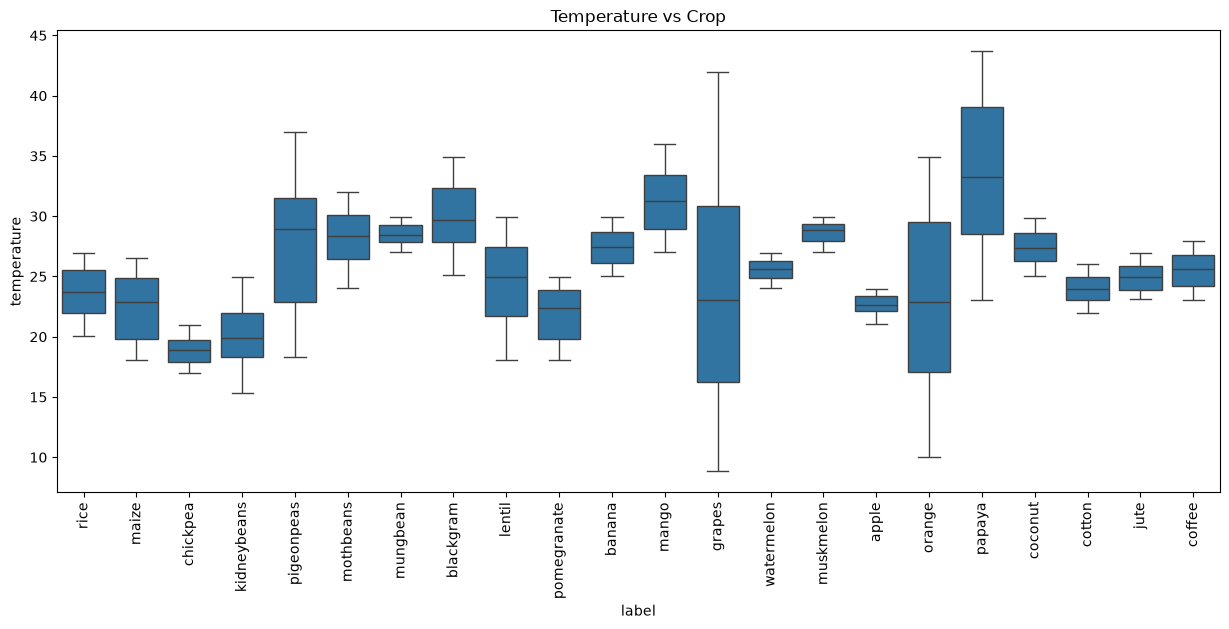

In [17]:
plt.figure(figsize=(15,6))
sns.boxplot(x='label', y='temperature', data=df)
plt.xticks(rotation=90)
plt.title("Temperature vs Crop")
plt.show()

### Observation

Different crops grow under different temperature ranges. Some crops prefer lower temperatures, while others require warmer climatic conditions.

## Bivariate Analysis

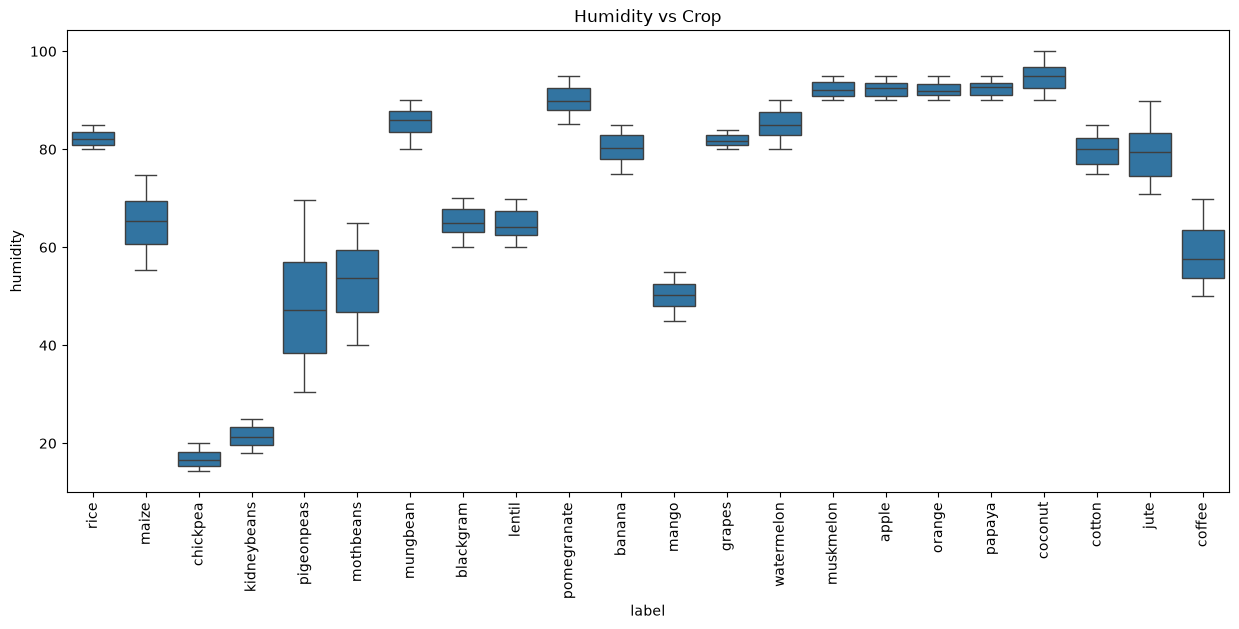

In [18]:
plt.figure(figsize=(15,6))
sns.boxplot(x='label', y='humidity', data=df)
plt.xticks(rotation=90)
plt.title("Humidity vs Crop")
plt.show()

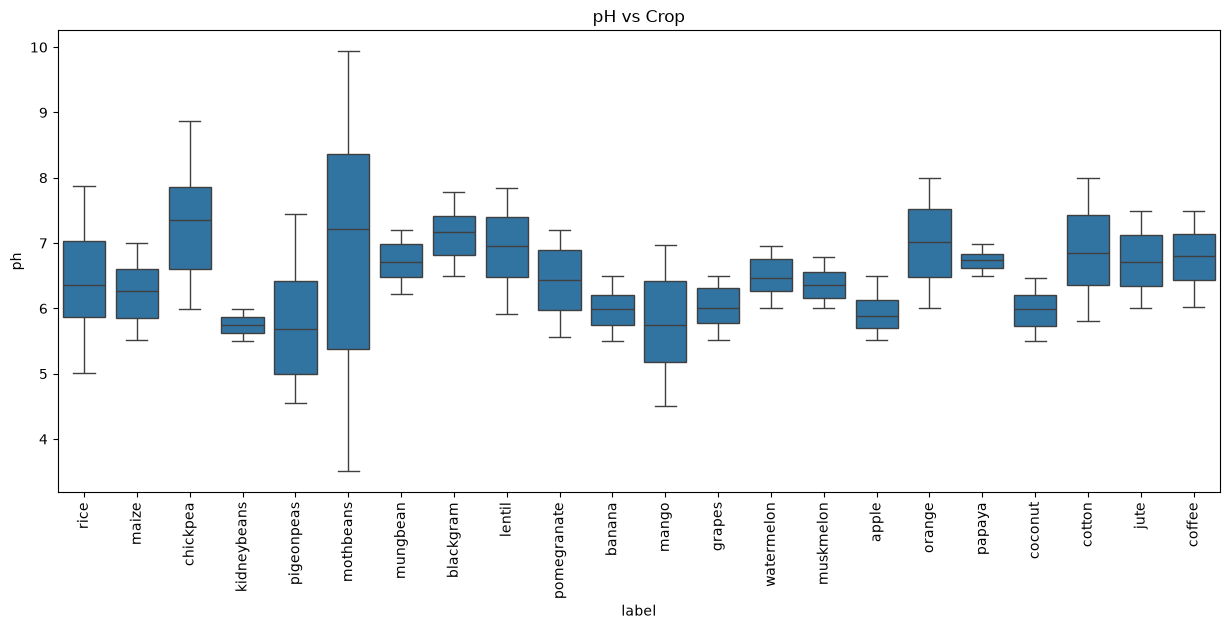

In [19]:
plt.figure(figsize=(15,6))
sns.boxplot(x='label', y='ph', data=df)
plt.xticks(rotation=90)
plt.title("pH vs Crop")
plt.show()

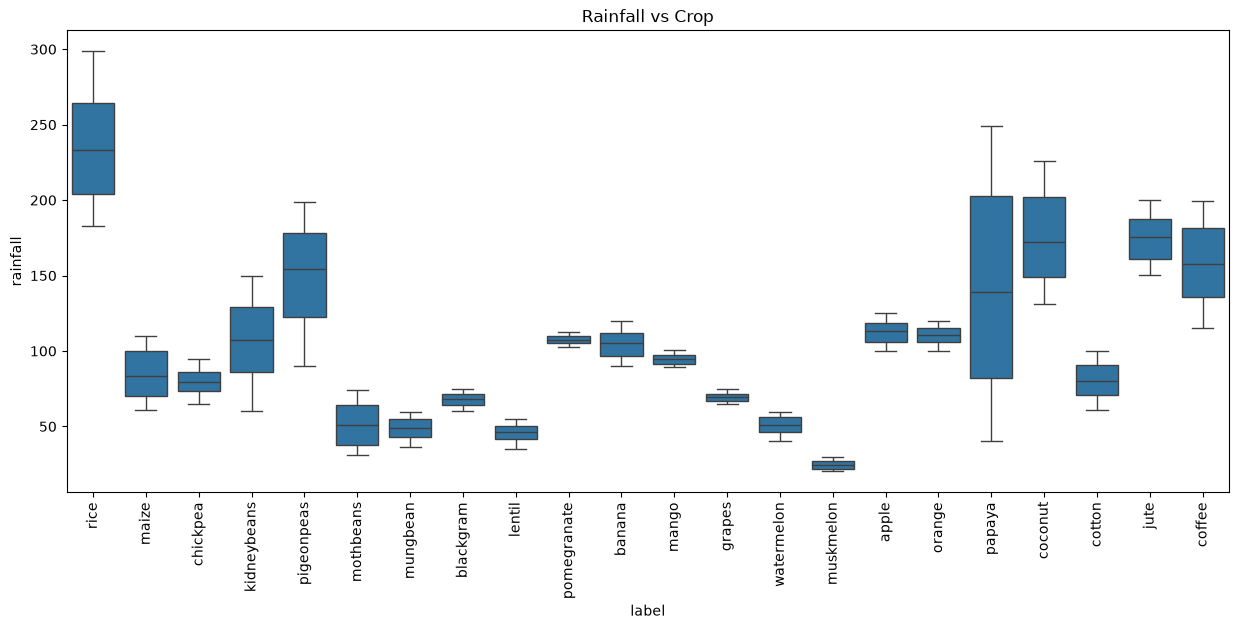

In [20]:
plt.figure(figsize=(15,6))
sns.boxplot(x='label', y='rainfall', data=df)
plt.xticks(rotation=90)
plt.title("Rainfall vs Crop")
plt.show()

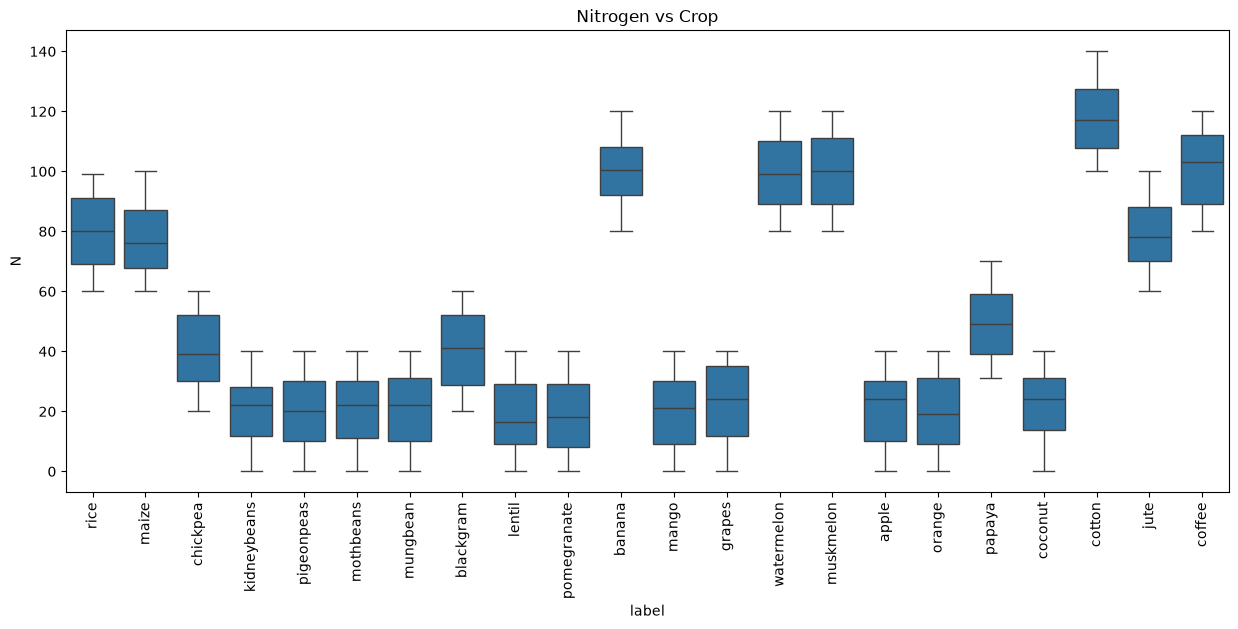

In [21]:
plt.figure(figsize=(15,6))
sns.boxplot(x='label', y='N', data=df)
plt.xticks(rotation=90)
plt.title("Nitrogen vs Crop")
plt.show()

In [22]:
correlation = df.drop('label', axis=1).corr()

correlation

,N,P,K,temperature,humidity,ph,rainfall
N,1.000000,-0.231460,-0.140512,0.026504,0.190688,0.096683,0.059020
P,-0.231460,1.000000,0.736232,-0.127541,-0.118734,-0.138019,-0.063839
K,-0.140512,0.736232,1.000000,-0.160387,0.190859,-0.169503,-0.053461
temperature,0.026504,-0.127541,-0.160387,1.000000,0.205320,-0.017795,-0.030084
humidity,0.190688,-0.118734,0.190859,0.205320,1.000000,-0.008483,0.094423
ph,0.096683,-0.138019,-0.169503,-0.017795,-0.008483,1.000000,-0.109069
rainfall,0.059020,-0.063839,-0.053461,-0.030084,0.094423,-0.109069,1.000000


## Multivariate Analysis

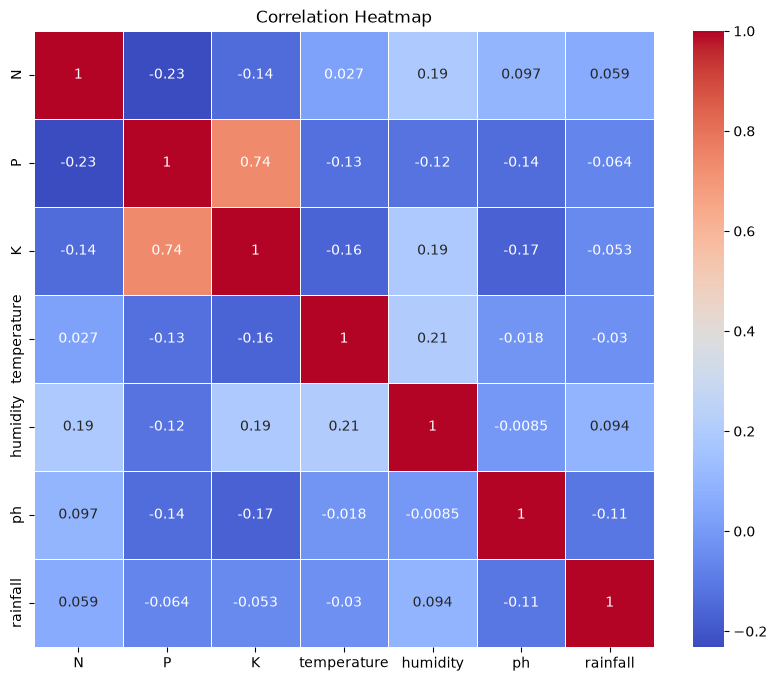

In [23]:
plt.figure(figsize=(10,8))
sns.heatmap(correlation, annot=True, cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

### Observation

The heatmap shows the correlation between all numerical features. Most features have weak to moderate correlations, indicating that each feature contributes unique information for crop prediction.

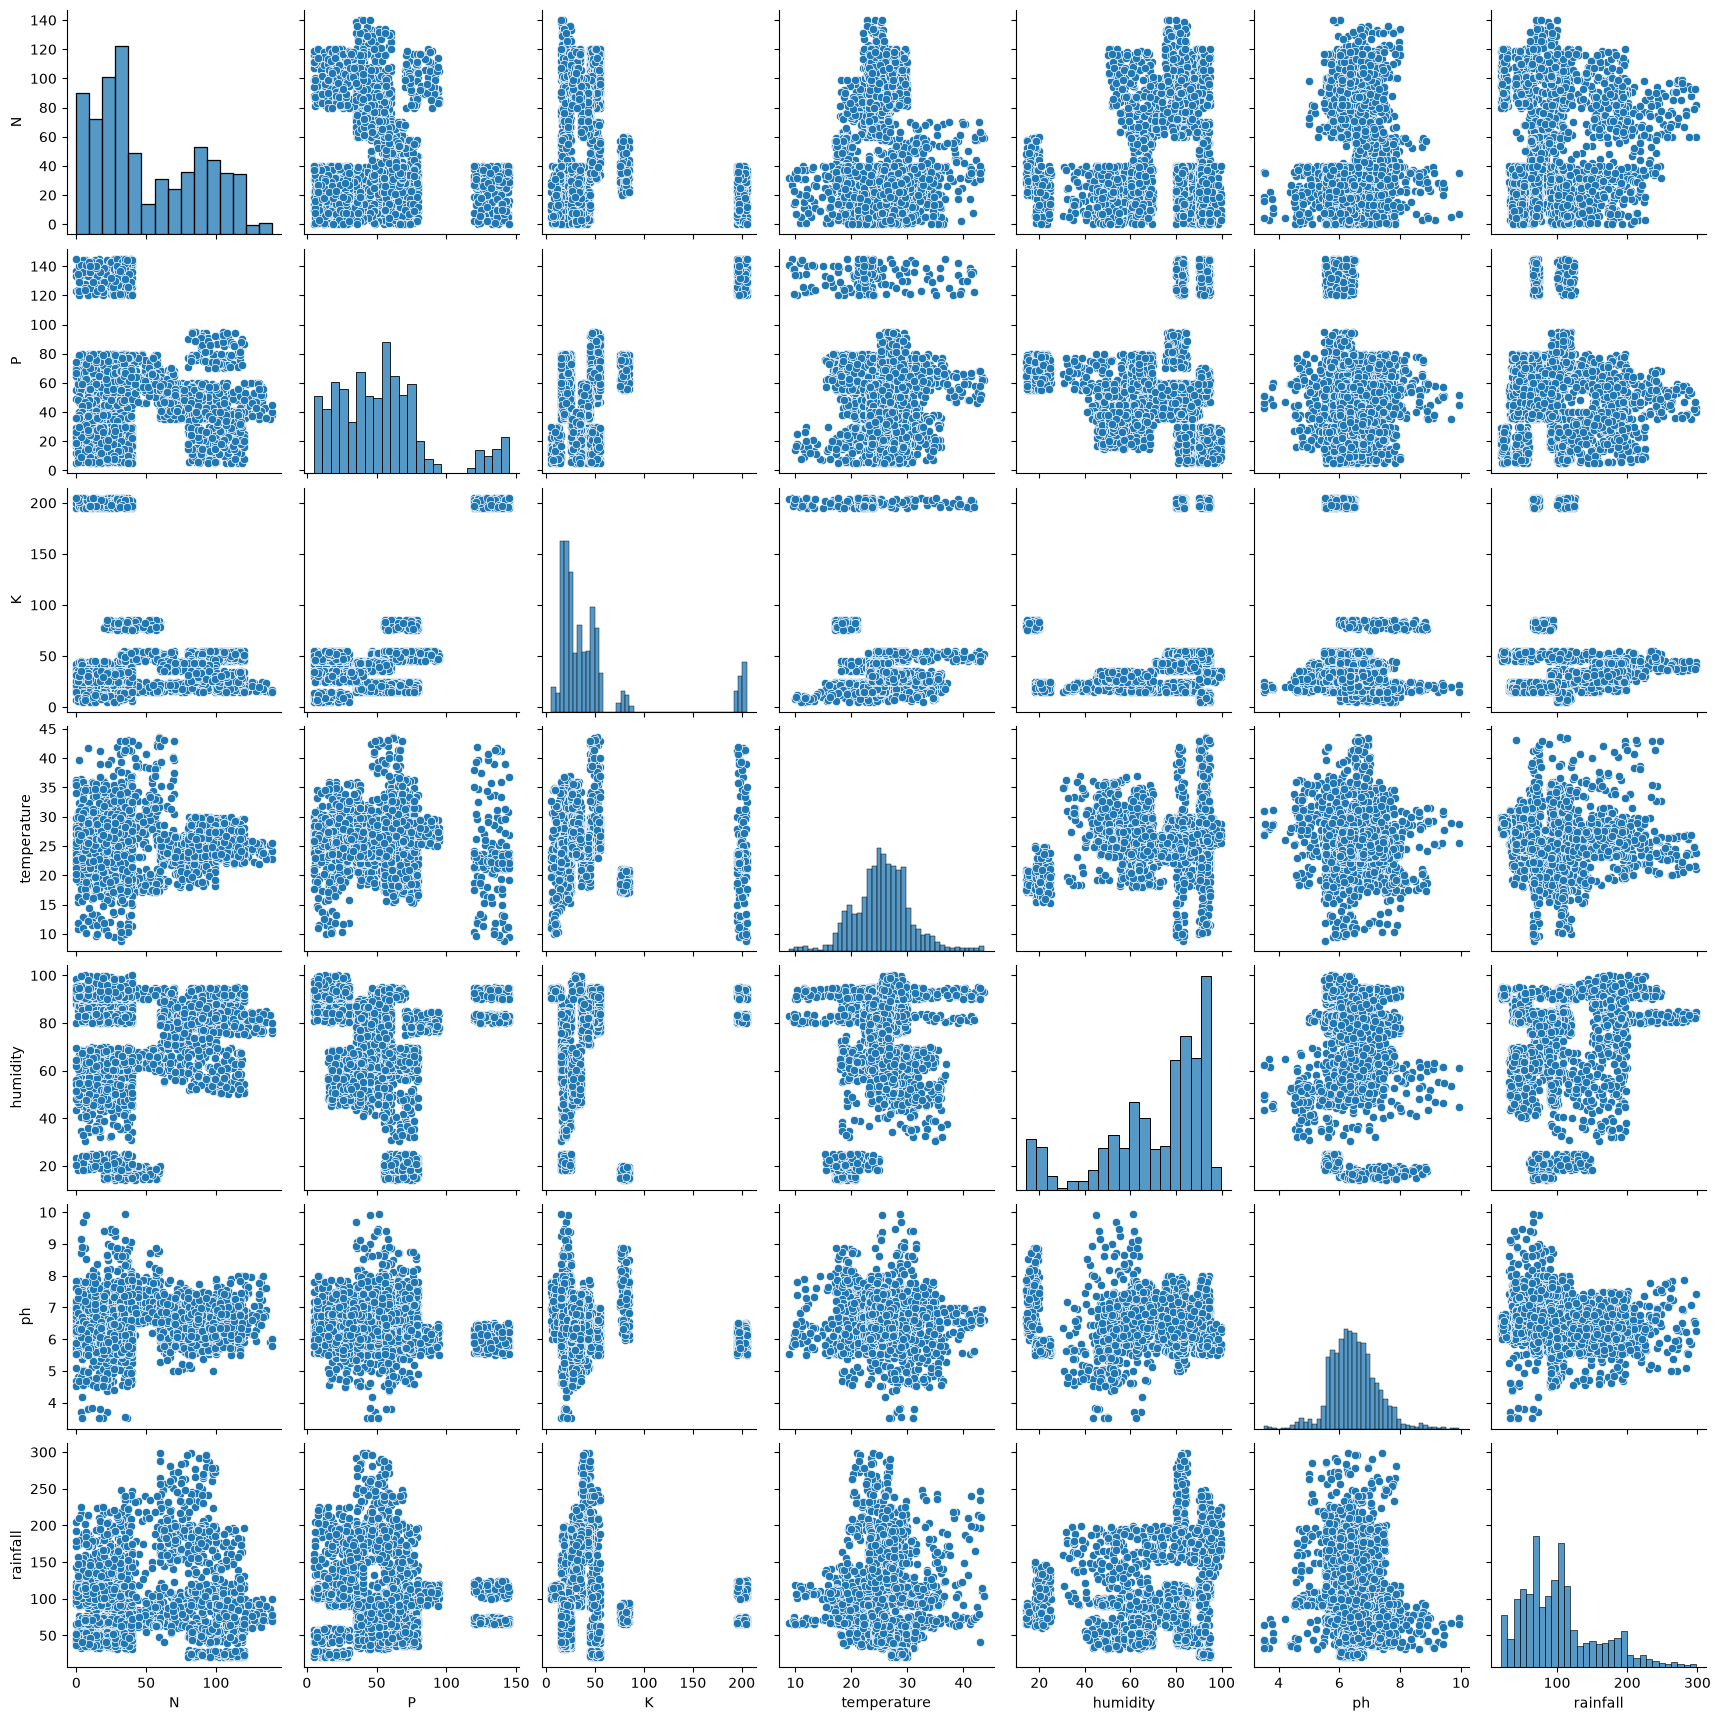

In [24]:
sns.pairplot(df[['N','P','K','temperature','humidity','ph','rainfall']])
plt.show()

### Observation

The pair plot visualizes relationships between all numerical features. It helps identify patterns, distributions, and possible relationships among multiple variables simultaneously.

## Checking for Null Values

In [25]:
import sys
!{sys.executable} -m pip install seaborn


[notice] A new release of pip is available: 24.3.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [26]:
df.isnull().sum()

N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

In [27]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


### Observation
The dataset contains no missing values across any of the 8 columns (N, P, K, temperature, humidity, ph, rainfall, label). All 2200 records are complete, so no imputation or row removal is required before moving to the next preprocessing step.

## Handling Outliers

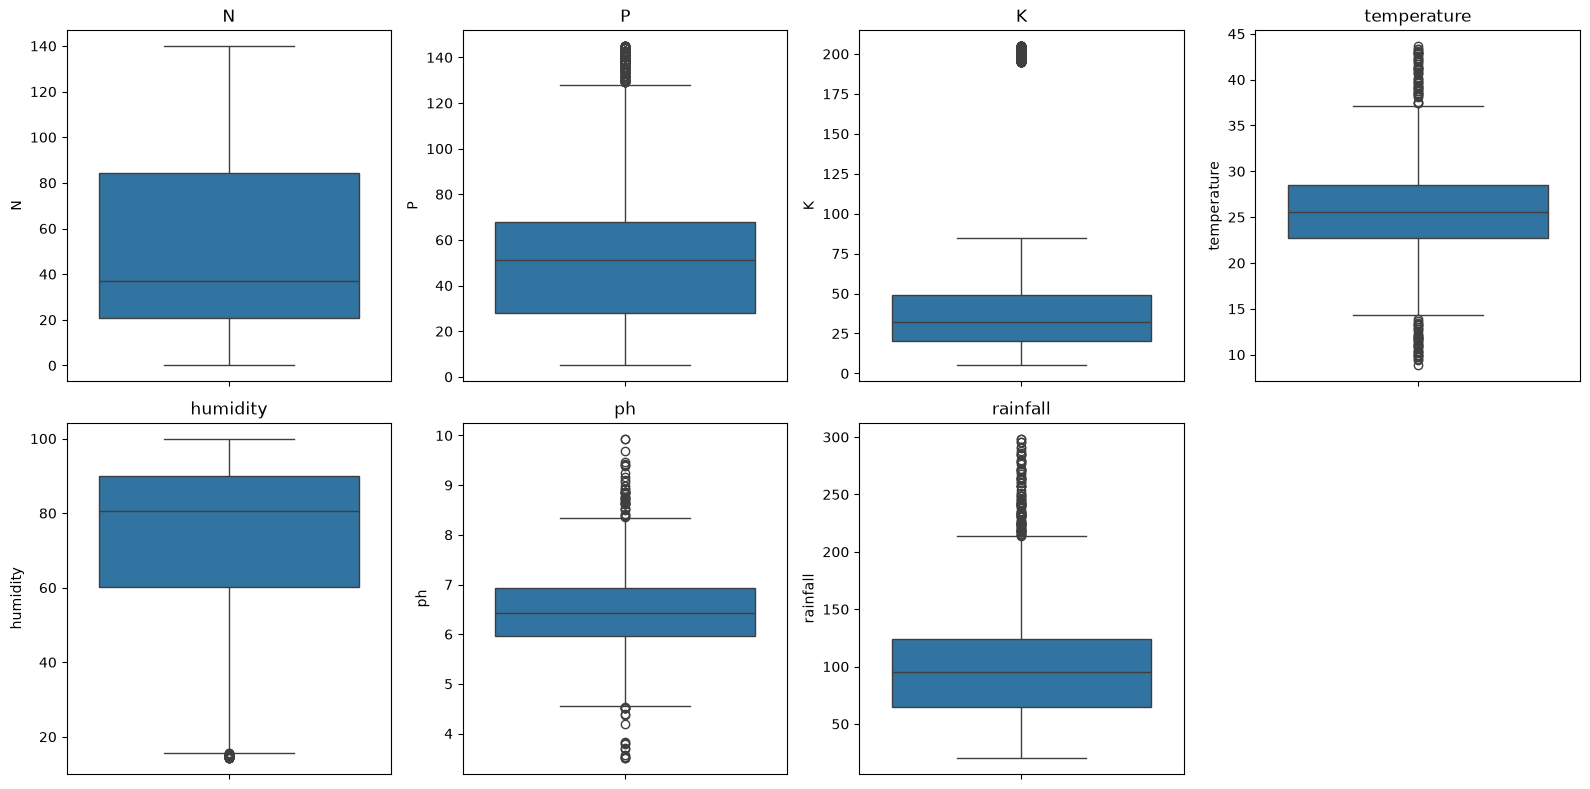

In [28]:
numeric_cols = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

plt.figure(figsize=(16, 8))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(2, 4, i)
    sns.boxplot(y=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

In [29]:
print(f"{'Feature':<14}{'Q1':>10}{'Q3':>10}{'IQR':>10}{'Lower':>12}{'Upper':>12}{'Outliers':>10}")
outlier_counts = {}
for col in numeric_cols:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_counts[col] = n_out
    print(f"{col:<14}{Q1:>10.2f}{Q3:>10.2f}{IQR:>10.2f}{lower:>12.2f}{upper:>12.2f}{n_out:>10}")

Feature               Q1        Q3       IQR       Lower       Upper  Outliers
N                  21.00     84.25     63.25      -73.88      179.12         0
P                  28.00     68.00     40.00      -32.00      128.00       138
K                  20.00     49.00     29.00      -23.50       92.50       200
temperature        22.77     28.56      5.79       14.08       37.25        86
humidity           60.26     89.95     29.69       15.73      134.48        30
ph                  5.97      6.92      0.95        4.54        8.35        57
rainfall           64.55    124.27     59.72      -25.02      213.84       100


### Observation
The boxplot and IQR analysis confirm that Potassium (K) has the highest number of outliers (200), with values clustering far above the upper bound. A log transformation is applied to normalize its distribution.

In [30]:
df['K_log'] = np.log1p(df['K'])
df[['K', 'K_log']].head()

,K,K_log
0,43,3.784190
1,41,3.737670
2,44,3.806662
3,40,3.713572
4,42,3.761200


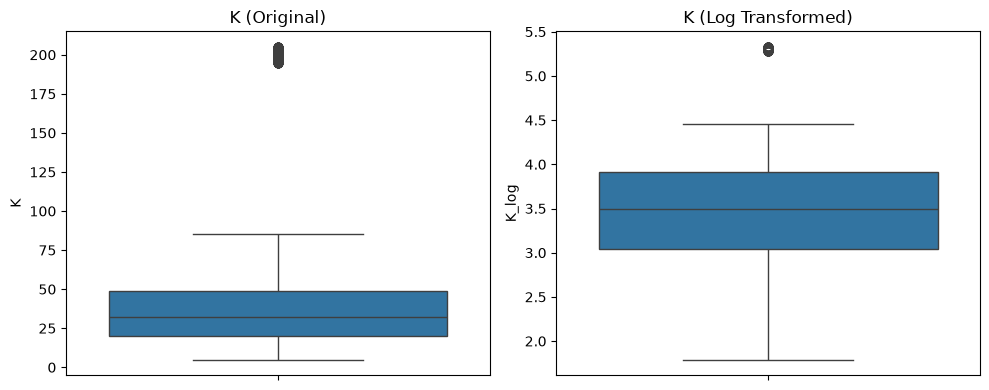

In [31]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.boxplot(y=df['K'])
plt.title('K (Original)')

plt.subplot(1, 2, 2)
sns.boxplot(y=df['K_log'])
plt.title('K (Log Transformed)')

plt.tight_layout()
plt.show()

### Observation
After applying log transformation, the distribution of Potassium becomes more compact and symmetric, significantly reducing the visual spread of outliers compared to the original feature.

## Extracting Seasonal Crops

In [32]:
crop_climate = df.groupby('label')[['temperature', 'humidity', 'rainfall']].mean()

def classify_season(row):
    if row['rainfall'] > 140:
        return 'Rainy'
    elif row['temperature'] < 23:
        return 'Winter'
    else:
        return 'Summer'

crop_climate['season'] = crop_climate.apply(classify_season, axis=1)
crop_climate.round(1)

,temperature,humidity,rainfall,season
label,,,,
apple,22.6,92.3,112.7,Winter
banana,27.4,80.4,104.6,Summer
blackgram,30.0,65.1,67.9,Summer
chickpea,18.9,16.9,80.1,Winter
coconut,27.4,94.8,175.7,Rainy
coffee,25.5,58.9,158.1,Rainy
cotton,24.0,79.8,80.4,Summer
grapes,23.8,81.9,69.6,Summer
jute,25.0,79.6,174.8,Rainy


In [33]:
print(crop_climate['season'].value_counts())

season_map = crop_climate['season'].to_dict()
df['season'] = df['label'].map(season_map)
df[['label', 'season']].head(10)

season
Summer    10
Winter     6
Rainy      6
Name: count, dtype: int64


,label,season
0,rice,Rainy
1,rice,Rainy
2,rice,Rainy
3,rice,Rainy
4,rice,Rainy
5,rice,Rainy
6,rice,Rainy
7,rice,Rainy
8,rice,Rainy
9,rice,Rainy


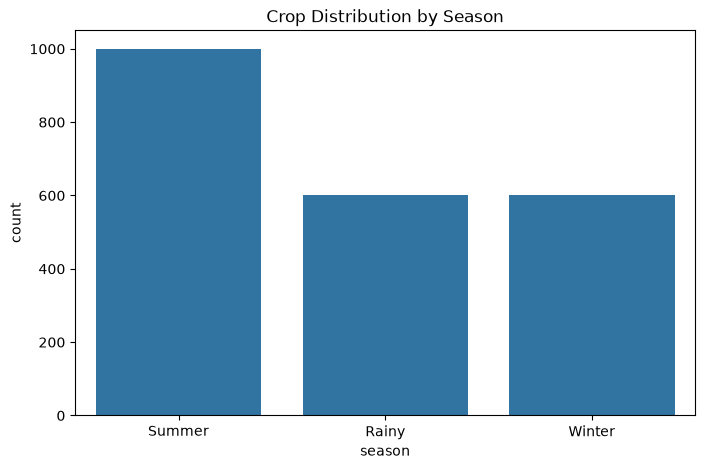

In [34]:
plt.figure(figsize=(8, 5))
sns.countplot(x='season', data=df, order=['Summer', 'Rainy', 'Winter'])
plt.title('Crop Distribution by Season')
plt.show()

### Observation
Crops were grouped by their average temperature, humidity, and rainfall to classify them into three seasons: Rainy (rainfall > 140mm, e.g. rice, coconut, coffee, jute), Winter (temperature < 23°C, e.g. apple, chickpea, kidneybeans), and Summer (the remaining warmer, drier crops). This seasonal tagging can support season-based crop recommendations.


## Splitting Data into Train and Test Sets

In [35]:
X = df[['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']]
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1760, 7)
X_test shape: (440, 7)
y_train shape: (1760,)
y_test shape: (440,)


In [36]:
X_train.assign(label=y_train).to_csv('../dataset/train.csv', index=False)
X_test.assign(label=y_test).to_csv('../dataset/test.csv', index=False)
print("Saved train.csv and test.csv to dataset folder")

Saved train.csv and test.csv to dataset folder


### Observation
The dataset was split into 80% training data (1760 samples) and 20% testing data (440 samples) using stratified sampling, ensuring all 22 crop classes are proportionally represented in both sets. This prepares the data for training the crop recommendation model.
